In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import matplotlib.font_manager as fm
font_path = '/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Times New Roman'

def load_pkl(file_path):
    with open(file_path, 'rb') as f:
        return pickle.load(f)

In [3]:
ind_cell_df = pd.read_csv('cell_positions_h01_rotated_full.csv')
ind_cell_df.rename({'Unnamed: 0': 'id_new'}, axis=1, inplace=True)

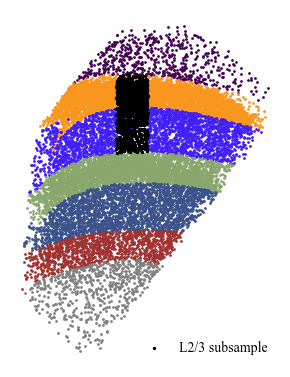

In [14]:
df = ind_cell_df.copy()

ind_cell_df_sub = df[(df['distance2Dcenter'] <= 160.98) & (df['z_new'] >= 4.0) & (df['z_new'] <= 170.0) & (df['layer'] >= 2) & (df['layer'] <= 3)]

layer_colors = {    1: "#440154",    2: "#f8961e",    3: "#421ef8",    4: "#89A66D",    5: "#3b528b",    6: "#A13232",    7: "gray",}

fig, ax = plt.subplots(figsize=(3, 4))
for layer, data in df.groupby("layer"):
    ax.scatter(data["x_new"], data["y_new"], s=1, color=layer_colors.get(layer, "gray"), rasterized=True)

ax.scatter(ind_cell_df_sub["x_new"], ind_cell_df_sub["y_new"], s=2, color="black", alpha=1.0, label="L2/3 subsample", rasterized=True)
ax.set_aspect("equal")
ax.axis("off")
ax.legend(frameon=False)
plt.tight_layout()
# plt.savefig("H01_neuron_positions_xy_subsample.pdf", dpi=600, bbox_inches="tight")
plt.show()

# L23 NN 1250

In [15]:
ind_cell_df_sub = ind_cell_df_sub.sort_values(by='layer')
ind_cell_df_sub = ind_cell_df_sub.sort_values(by='z_new') 
ind_cell_df_sub = ind_cell_df_sub.sort_values(by='EI')
ind_cell_df_sub = ind_cell_df_sub.reset_index(drop=True) 
print(f"Ntotal = {len(ind_cell_df_sub)}, N exc = {len(ind_cell_df_sub[ind_cell_df_sub['EI'] == 'excitatory'])}, N inh = {len(ind_cell_df_sub[ind_cell_df_sub['EI'] == 'inhibitory'])}")
print(f"Fraction exc = {(len(ind_cell_df_sub[ind_cell_df_sub['EI'] == 'excitatory']) / len(ind_cell_df_sub))*100}%, Fraction inh = {(len(ind_cell_df_sub[ind_cell_df_sub['EI'] == 'inhibitory']) / len(ind_cell_df_sub))*100}%")
ind_cell_df = ind_cell_df_sub
edges_pre_post = np.loadtxt('edges_pre_post.txt')
print('Edges loaded')

N_inh = len(ind_cell_df_sub[ind_cell_df_sub['EI'] == 'inhibitory'])

frac_sst = 0.25
frac_pv = 0.35
frac_vip = 0.4

N_sst = int(round(frac_sst * N_inh))
N_pv = int(round(frac_pv * N_inh))
N_vip = N_inh - N_sst - N_pv

ind_cell_df_sub.loc[ind_cell_df_sub['EI'] == 'excitatory', 'type'] = 'PYR'
ind_cell_df_sub.loc[ind_cell_df_sub['EI'] == 'inhibitory', 'type'] = 'VIP'

# Get indices of the VIP rows
vip_idx = ind_cell_df_sub.index[ind_cell_df_sub["type"] == "VIP"].to_numpy()

# Check that there are enough VIP cells
assert len(vip_idx) >= N_sst + N_pv + N_vip, "Not enough VIP elements"

# Reproducible random generator
SEED = 1223
rng = np.random.default_rng(SEED)

# Shuffle inhibitory-cell identities
rng.shuffle(vip_idx)

# Assign the new types
start = 0
ind_cell_df_sub.loc[vip_idx[start:start + N_sst], "type"] = "SST"
start += N_sst
ind_cell_df_sub.loc[vip_idx[start:start + N_pv], "type"] = "PV"
start += N_pv
ind_cell_df_sub.loc[vip_idx[start:start + N_vip], "type"] = "VIP"

pop_order = ["PYR", "SST", "PV", "VIP"]

ind_cell_df_sub["type"] = pd.Categorical(
    ind_cell_df_sub["type"],
    categories=pop_order,
    ordered=True
)

ind_cell_df_sub = (
    ind_cell_df_sub
    .sort_values(["type"])
    .reset_index(drop=True)
)


ind_cell_df = ind_cell_df_sub.copy()
N_population = ind_cell_df_sub['type'].value_counts()
print(N_population)

Ntotal = 1250, N exc = 800, N inh = 450
Fraction exc = 64.0%, Fraction inh = 36.0%
Edges loaded
PYR    800
VIP    180
PV     158
SST    112
Name: type, dtype: int64


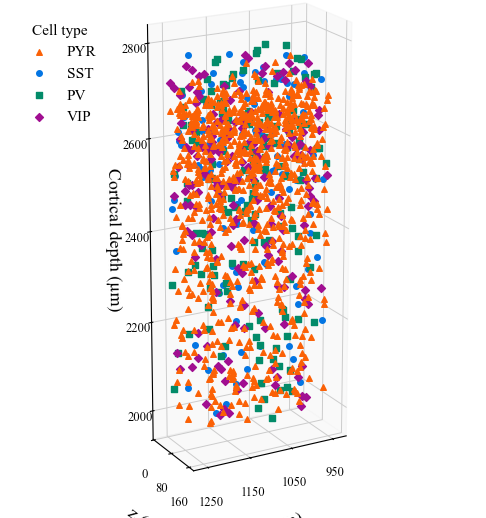

In [40]:
df = ind_cell_df_sub[["x_new", "y_new", "z_new", "type"]].dropna().copy()
type_colors = {    "PYR": "#fb6106",    "VIP": "#a10e91",    "PV":  "#038b69",    "SST": "#0375e3",}

type_markers = {
    "PYR": "^",   # triangle
    "SST": "o",   # circle
    "PV":  "s",   # square
    "VIP": "D",   # diamond
}
type_order = ["PYR", "SST", "PV", "VIP"]
elev = 19.2
azim = 60.9
roll = 0

fig = plt.figure(figsize=(5, 15))
ax = fig.add_subplot(111, projection="3d")

for cell_type in type_order:
    data = df[df["type"] == cell_type]
    ax.scatter(data["x_new"], data["z_new"], data["y_new"], s=16, color=type_colors[cell_type], marker=type_markers[cell_type], label=cell_type, depthshade=False, rasterized=True)

ax.set_box_aspect((np.ptp(df["x_new"]), np.ptp(df["z_new"]), np.ptp(df["y_new"])))
ax.view_init(elev=elev, azim=azim, roll=roll)
ax.set_proj_type("persp")
ax.set_xlabel("x (µm)", labelpad=8)
ax.set_zlabel("Cortical depth (µm)", labelpad=12)
ax.set_ylabel("z (µm)", labelpad=8)
ax.set_xticks([950, 1050, 1150, 1250])
ax.set_zticks([2000, 2200, 2400, 2600, 2800])
ax.set_yticks([0, 80, 160])
ax.tick_params(axis='x', labelsize=9)
ax.tick_params(axis='y', labelsize=9)
ax.tick_params(axis='z', labelsize=9)
ax.grid(True)
# Light pane colors to keep the 3D look
ax.xaxis.pane.set_facecolor((0.96, 0.96, 0.96, 1.0))
ax.yaxis.pane.set_facecolor((0.96, 0.96, 0.96, 1.0))
ax.zaxis.pane.set_facecolor((0.96, 0.96, 0.96, 1.0))
# Light grid lines
for axis in [ax.xaxis, ax.yaxis, ax.zaxis]:
    axis._axinfo["grid"]["color"] = (0.80, 0.80, 0.80, 1.0)
    axis._axinfo["grid"]["linewidth"] = 0.7
    axis._axinfo["grid"]["linestyle"] = "-"

ax.legend(title="Cell type", frameon=False, loc="upper left")
plt.tight_layout()
# plt.savefig("H01_L23_subsample_3D_matplotlib.pdf", dpi=600, bbox_inches="tight", transparent=True)
plt.show()